# Project 2: MovieLens User–Movie Network
**Sachi Kapoor | DATA 620**

## Research question
How does retaining higher-rated user–movie connections change the network, and what can the resulting structure tell us about users and movies?

## Project overview
This project analyzes MovieLens 100K as a two-mode network. The two groups are users and movies. An edge connects a user to a movie they rated, and its weight is the rating from 1 to 5.

I will compare rating thresholds to reduce the network, measure how its structure changes, and examine patterns in both groups. A missing connection means no recorded rating, not necessarily dislike.

Source: https://grouplens.org/datasets/movielens/100k/

In [1]:
import io
import zipfile
from urllib.request import urlopen

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load the uploaded MovieLens ZIP
archive = zipfile.ZipFile("ml-100k (2).zip")

ratings = pd.read_csv(
    archive.open("ml-100k/u.data"),
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print(f"Ratings: {len(ratings):,}")
print(f"Users: {ratings['user_id'].nunique():,}")
print(f"Movies: {ratings['movie_id'].nunique():,}")
print(f"Missing values: {ratings.isna().sum().sum()}")
print(
    "Duplicate user–movie pairs:",
    ratings.duplicated(["user_id", "movie_id"]).sum()
)

display(ratings.head())

Ratings: 100,000
Users: 943
Movies: 1,682
Missing values: 0
Duplicate user–movie pairs: 0


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
# Create a network with two distinct node groups
B = nx.Graph()

B.add_nodes_from(
    [f"user_{uid}" for uid in ratings["user_id"].unique()],
    bipartite=0,
    node_type="user"
)

B.add_nodes_from(
    [f"movie_{mid}" for mid in ratings["movie_id"].unique()],
    bipartite=1,
    node_type="movie"
)

# Each edge represents a recorded rating
B.add_weighted_edges_from(
    (f"user_{row.user_id}", f"movie_{row.movie_id}", row.rating)
    for row in ratings.itertuples(index=False)
)

# Verify that all connections run between the two groups
assert all(
    B.nodes[u]["node_type"] != B.nodes[v]["node_type"]
    for u, v in B.edges()
)

print(f"Total nodes: {B.number_of_nodes():,}")
print(f"Total edges: {B.number_of_edges():,}")
print(f"Is bipartite: {nx.is_bipartite(B)}")
print(f"Connected components: {nx.number_connected_components(B):,}")

Total nodes: 2,625
Total edges: 100,000
Is bipartite: True
Connected components: 1


## Network reduction method

I compare minimum rating thresholds from 1 to 5. At each threshold,
I retain ratings at or above that value and remove isolated nodes.

This focuses the network on more favorable ratings. It does not mean
that lower ratings are unimportant or that removed users and movies
are unimportant. I compare how many users, movies, edges, and connected
components remain before choosing a threshold.

In [4]:
threshold_networks = {}
summary_rows = []

for threshold in range(1, 6):
    # Retain edges meeting the minimum rating
    kept_edges = [
        (u, v)
        for u, v, data in B.edges(data=True)
        if data["weight"] >= threshold
    ]

    # Edge subgraph includes only nodes with retained connections
    H = B.edge_subgraph(kept_edges).copy()
    threshold_networks[threshold] = H

    users_remaining = sum(
        data["node_type"] == "user"
        for _, data in H.nodes(data=True)
    )
    movies_remaining = H.number_of_nodes() - users_remaining
    components = list(nx.connected_components(H))
    largest_size = max(map(len, components), default=0)

    summary_rows.append({
        "Minimum rating": threshold,
        "Users": users_remaining,
        "Movies": movies_remaining,
        "Edges": H.number_of_edges(),
        "Edges retained (%)": round(
            100 * H.number_of_edges() / B.number_of_edges(), 2
        ),
        "Components": len(components),
        "Largest component nodes": largest_size
    })

threshold_summary = pd.DataFrame(summary_rows)
display(threshold_summary)

,Minimum rating,Users,Movies,Edges,Edges retained (%),Components,Largest component nodes
0,1,943,1682,100000,100.00,1,2625
1,2,943,1612,93890,93.89,1,2555
2,3,943,1574,82520,82.52,1,2517
3,4,942,1447,55375,55.38,1,2389
4,5,928,1172,21201,21.20,1,2100


## Selected reduction: Five-star ratings

I selected a minimum rating of 5 to focus on users' highest-rated
movie connections. This retains 21,201 edges, or 21.2% of the original
ratings, along with 928 users and 1,172 movies.

The reduced network still forms one connected component. Therefore,
rating thresholding substantially reduces its size but does not
separate it into disconnected islands.

This is an edge-weight threshold approach. Ratings measure preference,
not interaction frequency, and users may differ in how readily they
award five stars. The reduced network describes recorded five-star
preferences rather than all viewing behavior.

In [5]:
# Select the reduced network
reduced = threshold_networks[5]

# Load movie IDs and titles from the same ZIP
movies = pd.read_csv(
    archive.open("ml-100k/u.item"),
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["movie_id", "title"]
)

# Compare five-star connections with total recorded ratings
movie_stats = ratings.groupby("movie_id").agg(
    total_ratings=("rating", "size"),
    mean_rating=("rating", "mean")
)

five_star_counts = (
    ratings.loc[ratings["rating"] == 5]
    .groupby("movie_id")
    .size()
)

movie_stats["five_star_ratings"] = (
    five_star_counts.reindex(movie_stats.index, fill_value=0)
)

movie_stats["five_star_share_pct"] = (
    100 * movie_stats["five_star_ratings"]
    / movie_stats["total_ratings"]
)

movie_stats = movie_stats.join(movies.set_index("movie_id"))

top_movies = movie_stats.sort_values(
    ["five_star_ratings", "total_ratings"],
    ascending=False
).head(10)

display(top_movies[
    ["title", "total_ratings", "five_star_ratings",
     "five_star_share_pct", "mean_rating"]
].round(2))

,title,total_ratings,five_star_ratings,five_star_share_pct,mean_rating
movie_id,,,,,
50,Star Wars (1977),583,325,55.75,4.36
100,Fargo (1996),508,227,44.69,4.16
127,"Godfather, The (1972)",413,214,51.82,4.28
174,Raiders of the Lost Ark (1981),420,202,48.10,4.25
56,Pulp Fiction (1994),394,188,47.72,4.06
318,Schindler's List (1993),298,186,62.42,4.47
98,"Silence of the Lambs, The (1991)",390,181,46.41,4.29
313,Titanic (1997),350,179,51.14,4.25
172,"Empire Strikes Back, The (1980)",367,172,46.87,4.20


## Findings about movies

Star Wars (1977) has the most connections in the five-star network,
with 325 users awarding it five stars. Its high degree indicates
broad five-star support within this dataset.

Rating counts and approval proportions measure different things.
Schindler's List has fewer five-star ratings (186), but a higher
five-star share among its recorded ratings (62.42%) than Star Wars
(55.75%). A movie's degree therefore reflects both its exposure
among participating users and their ratings, rather than quality alone.

In [6]:
# Summarize each user's recorded rating activity
user_stats = ratings.groupby("user_id").agg(
    total_ratings=("rating", "size"),
    mean_rating=("rating", "mean")
)

user_fives = (
    ratings.loc[ratings["rating"] == 5]
    .groupby("user_id")
    .size()
)

user_stats["five_star_ratings"] = (
    user_fives.reindex(user_stats.index, fill_value=0)
)

user_stats["five_star_share_pct"] = (
    100 * user_stats["five_star_ratings"]
    / user_stats["total_ratings"]
)

print("Users with the most five-star connections:")
display(
    user_stats.sort_values(
        ["five_star_ratings", "total_ratings"],
        ascending=False
    ).head(10).round(2)
)

print("Distribution across all 943 users:")
display(
    user_stats[
        ["total_ratings", "five_star_ratings", "five_star_share_pct"]
    ].describe().round(2)
)

Users with the most five-star connections:


,total_ratings,mean_rating,five_star_ratings,five_star_share_pct
user_id,,,,
416,493,3.85,172,34.89
7,403,3.97,161,39.95
90,300,4.22,147,49.00
592,360,3.81,145,40.28
747,293,4.05,142,48.46
312,223,4.38,139,62.33
551,334,3.80,137,41.02
13,636,3.10,136,21.38
59,382,3.93,134,35.08


Distribution across all 943 users:


,total_ratings,five_star_ratings,five_star_share_pct
count,943.00,943.00,943.00
mean,106.04,22.48,23.08
std,100.93,24.97,15.18
min,20.00,0.00,0.00
25%,33.00,6.00,11.81
50%,65.00,14.00,20.65
75%,148.00,30.00,31.90
max,737.00,172.00,91.67


## Findings about users

Across all 943 users, the median number of recorded ratings is 65,
and the median number of five-star ratings is 14. The mean number
of five-star ratings is higher, at 22.48, indicating that some users
contribute substantially more five-star connections than others.

User 416 has the most five-star connections (172), out of 493 ratings.
However, user 312 awards five stars to a larger proportion of their
rated movies: 62.33%, compared with 34.89% for user 416.

User degree in the reduced network therefore reflects both recorded
rating activity and rating tendencies. It should not be interpreted
as social influence. Fifteen users have no five-star ratings and
are excluded from the reduced network.

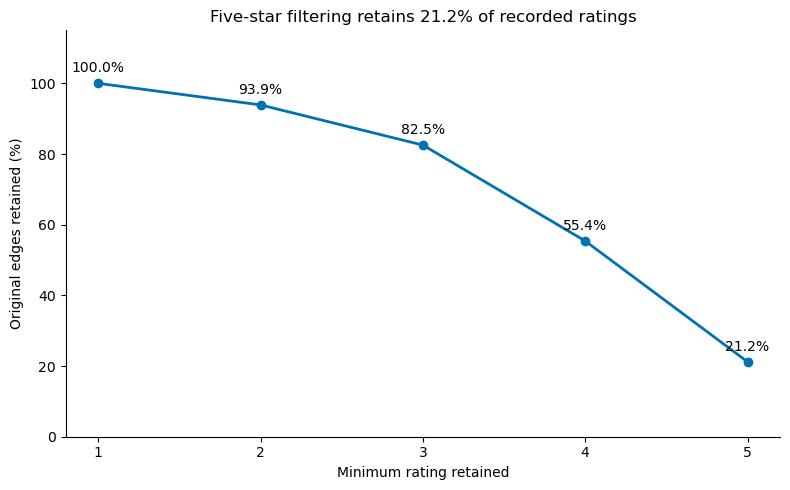

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    threshold_summary["Minimum rating"],
    threshold_summary["Edges retained (%)"],
    marker="o",
    color="#0072B2",
    linewidth=2
)

for _, row in threshold_summary.iterrows():
    ax.annotate(
        f'{row["Edges retained (%)"]:.1f}%',
        (row["Minimum rating"], row["Edges retained (%)"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

ax.set(
    title="Five-star filtering retains 21.2% of recorded ratings",
    xlabel="Minimum rating retained",
    ylabel="Original edges retained (%)",
    xticks=[1, 2, 3, 4, 5],
    ylim=(0, 115)
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

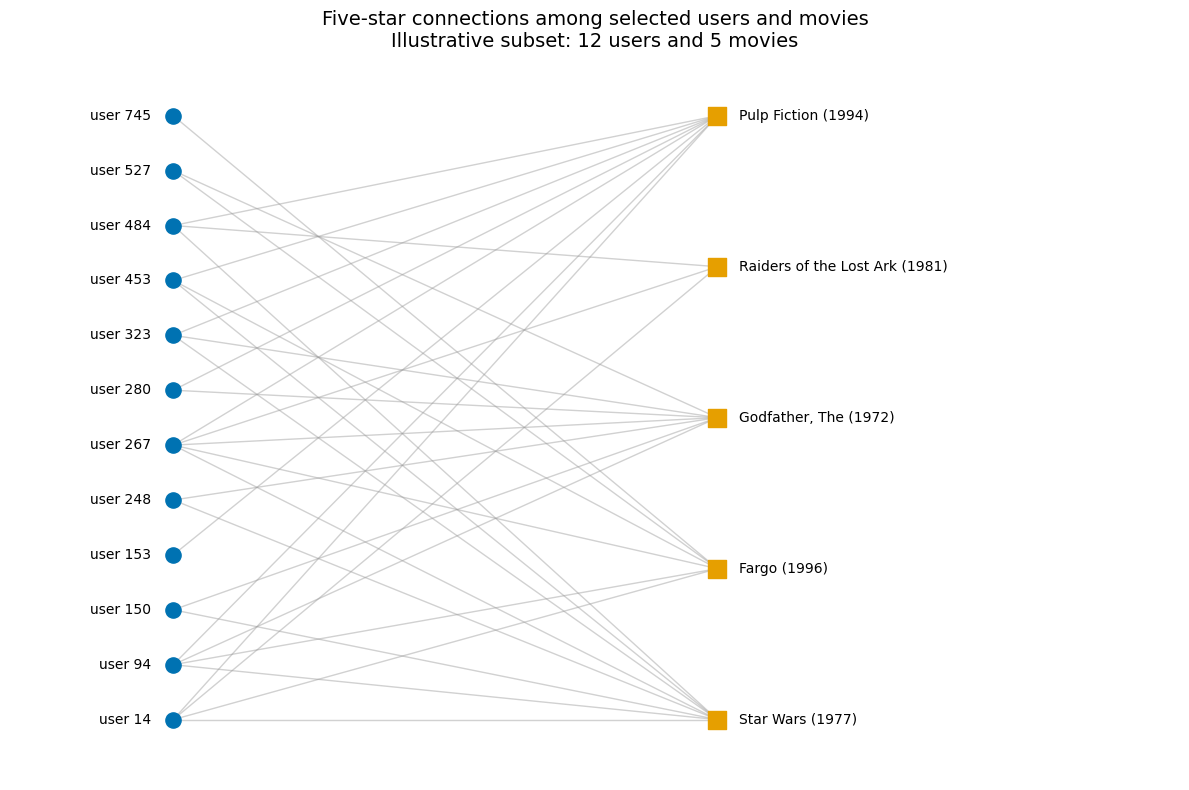

Displayed nodes: 17
Displayed edges: 32


In [8]:
# Display the top 5 movies and a reproducible random sample
# of 12 users connected to those movies.
selected_movies = [
    f"movie_{mid}" for mid in top_movies.index[:5]
]

candidate_users = {
    user
    for movie in selected_movies
    for user in reduced.neighbors(movie)
}

import random

# Reproducible sample of users connected to these five movies
selected_users = random.Random(42).sample(
    sorted(candidate_users),
    k=min(12, len(candidate_users))
)

selected_users = sorted(
    selected_users,
    key=lambda user: int(user.split("_")[1])
)

view = reduced.subgraph(selected_users + selected_movies).copy()

# Fixed positions keep the two node groups separate
pos = {
    user: (0, i / (len(selected_users) - 1))
    for i, user in enumerate(selected_users)
}
pos.update({
    movie: (1, i / (len(selected_movies) - 1))
    for i, movie in enumerate(selected_movies)
})

title_lookup = movies.set_index("movie_id")["title"].to_dict()

fig, ax = plt.subplots(figsize=(12, 8))

nx.draw_networkx_edges(
    view, pos, ax=ax, edge_color="#999999", alpha=0.45
)
nx.draw_networkx_nodes(
    view, pos, nodelist=selected_users,
    node_color="#0072B2", node_shape="o",
    node_size=120, ax=ax
)
nx.draw_networkx_nodes(
    view, pos, nodelist=selected_movies,
    node_color="#E69F00", node_shape="s",
    node_size=180, ax=ax
)

for user in selected_users:
    x, y = pos[user]
    ax.text(x - 0.04, y, user.replace("_", " "),
            ha="right", va="center", fontsize=10)

for movie in selected_movies:
    x, y = pos[movie]
    movie_id = int(movie.split("_")[1])
    ax.text(x + 0.04, y, title_lookup[movie_id],
            ha="left", va="center", fontsize=10)

ax.set_title(
    "Five-star connections among selected users and movies\n"
    "Illustrative subset: 12 users and 5 movies",
    fontsize=14
)
ax.set_xlim(-0.3, 1.85)
ax.set_ylim(-0.1, 1.1)
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Displayed nodes: {view.number_of_nodes()}")
print(f"Displayed edges: {view.number_of_edges()}")

## Interpreting the network visualization

Blue circles represent users, orange squares represent movies, and
each edge represents a five-star rating.

The diagram displays the five movies with the most five-star ratings
and a reproducible random sample of 12 users who gave at least one
of those movies five stars. All five-star edges between these selected
nodes are shown, producing 17 nodes and 32 edges.

Some users connect to several selected movies, illustrating shared
positive preferences. These connections do not establish friendships
or communication between users.

This illustration is not representative of the entire network:
it focuses on popular movies and users connected to them. An absent
edge can mean either a lower rating or no recorded rating.

## Conclusion and limitations

MovieLens 100K forms a two-mode network connecting 943 users to
1,682 movies through 100,000 recorded ratings.

Retaining only five-star ratings reduces the network to 928 users,
1,172 movies, and 21,201 edges. Despite removing approximately 78.8%
of edges, the remaining network is still connected. The filtering
therefore reduces size without producing disconnected islands.

For movies, high degree indicates many five-star ratings, but also
reflects how widely a movie was rated. Star Wars has the most five-star
connections, while Schindler's List has a higher five-star proportion
among its recorded ratings.

For users, high degree reflects both rating activity and willingness
to award five stars. It does not measure social influence.

These historical ratings describe participating MovieLens users,
not all movie viewers or current preferences. Missing ratings do not
indicate dislike, and five-star filtering excludes less favorable
opinions. The results are descriptive and do not establish causation.

## Reproducibility

Place ml-100k.zip in the same folder as this notebook and run the
cells from top to bottom. The visualization uses random seed 42.

Data source: GroupLens, MovieLens 100K
https://grouplens.org/datasets/movielens/100k/